## 포트폴리오 정리본 안내

원본 팀 분석 노트북을 보존하면서 입력 경로와 설치 안내만 정리했습니다. 저장된 출력은 기존 실행 결과이며 이 저장소 정리 과정에서 재학습하지 않았습니다.

타겟은 `segment == Dormant User`입니다. 실제 해지 라벨이나 미래 이탈 예측이 아닙니다. 평가상의 제약은 [기술보고서](../reports/technical_report.md)를 참고하세요.

In [1]:
# 환경 설정
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 모델링 및 평가 도구
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV , RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
from xgboost import XGBClassifier
import lightgbm as lgb      # LGBMClassifier
from sklearn.metrics import (
    confusion_matrix,      # 혼동 행렬
    accuracy_score,       # 정확도
    precision_score,      # 정밀도
    recall_score,         # 재현율
    f1_score,             # 정밀도와 재현율의 조화 평균
    classification_report, # 주요 평가지표 종합 리포트
    roc_curve,            # ROC 곡선 생성을 위한 FPR, TPR 계산
    roc_auc_score,        # AUC 점수 계산
    precision_recall_curve # 임계값 조정을 위한 P-R 곡선 계산
)

# Colab 한글 폰트
# 패키지 설치는 저장소 루트의 requirements.txt를 사용하세요.
import koreanize_matplotlib

# 경고 숨김
import warnings
warnings.filterwarnings('ignore')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 44.7 MB/s eta 0:00:00


In [5]:
# 파일 업로드
df = pd.read_csv("../data/processed/user_behavior_segment.csv")


In [6]:
# 처음 5행
df.head()

      user_id              segment  consumption_score  discovery_score  \
0  user_00001                Binge               0.75          0.66667   
1  user_00002       Engaged Critic               0.75          0.83333   
2  user_00003  Algorithm Dependent               0.75          0.00000   
3  user_00004                Binge               1.00          0.50000   
4  user_00005       Engaged Critic               0.50          0.50000   

   engagement_score  recency_score  age  gender country subscription_plan  \
0              0.25           0.75  40대    Male     USA             Basic   
1              1.00           0.50  30대    Male     USA       PremiumPlus   
2              0.50           1.00  30대  Female     USA          Standard   
3              1.00           0.25  10대    Male     USA          Standard   
4              1.00           1.00  20대  Female     USA          Standard   

   ...  avg_watch_pct  last_watch_date watch_genre_cnt  watch_original_ratio  \
0  ...      

In [7]:
# 데이터 크기(행, 열)
df.shape

(10000, 28)

In [8]:
# 데이터 타입
df.dtypes

user_id                  object
segment                  object
consumption_score       float64
discovery_score         float64
engagement_score        float64
recency_score           float64
age                      object
gender                   object
country                  object
subscription_plan        object
is_active                 int64
monthly_spend           float64
primary_device           object
household_size            int64
created_at               object
total_watch_cnt           int64
total_watch_minutes     float64
avg_watch_minutes       float64
avg_watch_pct           float64
last_watch_date          object
watch_genre_cnt           int64
watch_original_ratio    float64
avg_watch_runtime       float64
recommendation_ctr      float64
total_search_cnt        float64
search_ctr              float64
total_review_cnt        float64
avg_review_rating       float64
dtype: object

In [9]:
# 전체 요약 (결측치 파악)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 28 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   user_id               10000 non-null  object 
 1   segment               10000 non-null  object 
 2   consumption_score     10000 non-null  float64
 3   discovery_score       10000 non-null  float64
 4   engagement_score      10000 non-null  float64
 5   recency_score         10000 non-null  float64
 6   age                   10000 non-null  object 
 7   gender                10000 non-null  object 
 8   country               10000 non-null  object 
 9   subscription_plan     10000 non-null  object 
 10  is_active             10000 non-null  int64  
 11  monthly_spend         10000 non-null  float64
 12  primary_device        10000 non-null  object 
 13  household_size        10000 non-null  int64  
 14  created_at            10000 non-null  object 
 15  total_watch_cnt     

In [10]:
# 기술통계 요약
df.describe()

       consumption_score  discovery_score  engagement_score  recency_score  \
count       10000.000000     10000.000000      10000.000000   10000.000000   
mean            0.625000         0.500000          0.625000       0.625000   
std             0.279522         0.262003          0.279522       0.279522   
min             0.250000         0.000000          0.250000       0.250000   
25%             0.437500         0.333330          0.437500       0.437500   
50%             0.625000         0.500000          0.625000       0.625000   
75%             0.812500         0.666670          0.812500       0.812500   
max             1.000000         1.000000          1.000000       1.000000   

          is_active  monthly_spend  household_size  total_watch_cnt  \
count  10000.000000   10000.000000    10000.000000     10000.000000   
mean       0.851900      16.403865        2.735500        10.000000   
std        0.355217      13.099341        1.474909         3.161044   
min        0.

In [11]:
# 결측치 개수 확인
df.isnull().sum()

user_id                    0
segment                    0
consumption_score          0
discovery_score            0
engagement_score           0
recency_score              0
age                        0
gender                     0
country                    0
subscription_plan          0
is_active                  0
monthly_spend              0
primary_device             0
household_size             0
created_at                 0
total_watch_cnt            0
total_watch_minutes        0
avg_watch_minutes          0
avg_watch_pct              0
last_watch_date            0
watch_genre_cnt            0
watch_original_ratio       0
avg_watch_runtime          0
recommendation_ctr        79
total_search_cnt         814
search_ctr               814
total_review_cnt        2239
avg_review_rating       2239
dtype: int64

In [12]:
# 원본 보존 위해 복사본 만들어 작업
df_clean = df.copy()

In [13]:
# 결측치 처리 - 0 대체
df_clean['recommendation_ctr'] = df_clean['recommendation_ctr'].fillna(0)
df_clean['total_search_cnt'] = df_clean['total_search_cnt'].fillna(0)
df_clean['search_ctr'] = df_clean['search_ctr'].fillna(0)
df_clean['total_review_cnt'] = df_clean['total_review_cnt'].fillna(0)
df_clean['avg_review_rating'] = df_clean['avg_review_rating'].fillna(0)

# avg_review_rating을 제외한 다른 결측 컬럼은 의미 상 0이 들어가는 것이 타당
# avg_review_ranting은 0으로 채우는 대신 리뷰 작성 여부를 나타내는 파생변수 생성 필요

In [14]:
# 파생변수 생성
df_clean['review_user'] = np.where(df_clean['total_review_cnt'] > 0, 1, 0)

In [15]:
# 확인
df_clean.isnull().sum()

user_id                 0
segment                 0
consumption_score       0
discovery_score         0
engagement_score        0
recency_score           0
age                     0
gender                  0
country                 0
subscription_plan       0
is_active               0
monthly_spend           0
primary_device          0
household_size          0
created_at              0
total_watch_cnt         0
total_watch_minutes     0
avg_watch_minutes       0
avg_watch_pct           0
last_watch_date         0
watch_genre_cnt         0
watch_original_ratio    0
avg_watch_runtime       0
recommendation_ctr      0
total_search_cnt        0
search_ctr              0
total_review_cnt        0
avg_review_rating       0
review_user             0
dtype: int64

In [16]:
# 확인
df_clean.describe()

       consumption_score  discovery_score  engagement_score  recency_score  \
count       10000.000000     10000.000000      10000.000000   10000.000000   
mean            0.625000         0.500000          0.625000       0.625000   
std             0.279522         0.262003          0.279522       0.279522   
min             0.250000         0.000000          0.250000       0.250000   
25%             0.437500         0.333330          0.437500       0.437500   
50%             0.625000         0.500000          0.625000       0.625000   
75%             0.812500         0.666670          0.812500       0.812500   
max             1.000000         1.000000          1.000000       1.000000   

          is_active  monthly_spend  household_size  total_watch_cnt  \
count  10000.000000   10000.000000    10000.000000     10000.000000   
mean       0.851900      16.403865        2.735500        10.000000   
std        0.355217      13.099341        1.474909         3.161044   
min        0.

In [17]:
# 데이터 타입 변환
df_clean['segment'] = df_clean['segment'].astype('category')
df_clean['age'] = df_clean['age'].astype('category')
df_clean['gender'] = df_clean['gender'].astype('category')
df_clean['country'] = df_clean['country'].astype('category')
df_clean['subscription_plan'] = df_clean['subscription_plan'].astype('category')
df_clean['primary_device'] = df_clean['primary_device'].astype('category')
df_clean['created_at'] = pd.to_datetime(df_clean['created_at'], format='%Y-%m-%d %H:%M:%S')
df_clean['last_watch_date'] = pd.to_datetime(df_clean['last_watch_date'], format='%Y-%m-%d')

In [18]:
# 확인
df_clean.dtypes

user_id                         object
segment                       category
consumption_score              float64
discovery_score                float64
engagement_score               float64
recency_score                  float64
age                           category
gender                        category
country                       category
subscription_plan             category
is_active                        int64
monthly_spend                  float64
primary_device                category
household_size                   int64
created_at              datetime64[ns]
total_watch_cnt                  int64
total_watch_minutes            float64
avg_watch_minutes              float64
avg_watch_pct                  float64
last_watch_date         datetime64[ns]
watch_genre_cnt                  int64
watch_original_ratio           float64
avg_watch_runtime              float64
recommendation_ctr             float64
total_search_cnt               float64
search_ctr               

In [19]:
# 빈도 집계 - is_active별 사용자 수 (비율)
df_clean['is_active'].value_counts(normalize=True)

is_active
1    0.8519
0    0.1481
Name: proportion, dtype: float64

In [20]:
# 그룹별 집계 - is_active 기준
df_clean.groupby('is_active').mean(numeric_only=True)

           consumption_score  discovery_score  engagement_score  \
is_active                                                         
0                   0.628798         0.500225          0.637407   
1                   0.624340         0.499961          0.622843   

           recency_score  monthly_spend  household_size  total_watch_cnt  \
is_active                                                                  
0               0.623734      16.066117        2.740716        10.013504   
1               0.625220      16.462581        2.734593         9.997652   

           total_watch_minutes  avg_watch_minutes  avg_watch_pct  \
is_active                                                          
0                   616.470425          61.731271      49.822166   
1                   616.949125          61.750091      49.993306   

           watch_genre_cnt  watch_original_ratio  avg_watch_runtime  \
is_active                                                             
0          

In [21]:
# 그룹별 집계 - segment 기준
df_clean.groupby('segment').mean(numeric_only=True)

                     consumption_score  discovery_score  engagement_score  \
segment                                                                     
Algorithm Dependent           0.431340         0.093025          0.710410   
Binge                         0.881900         0.456424          0.564564   
Dormant User                  0.406980         0.519957          0.461011   
Engaged Critic                0.448702         0.540728          0.911974   
Explorer                      0.520428         0.832295          0.518288   

                     recency_score  is_active  monthly_spend  household_size  \
segment                                                                        
Algorithm Dependent       0.732558   0.850498      16.050498        2.754153   
Binge                     0.523903   0.847462      16.219532        2.742730   
Dormant User              0.926256   0.860397      16.795718        2.710864   
Engaged Critic            0.600024   0.836435      16.454917

In [22]:
# 그룹별 집계 - 리뷰 작성 여부별 집계
df_clean.groupby('review_user')[['total_review_cnt', 'avg_review_rating']].agg(['count', 'mean', 'median', 'max'])

            total_review_cnt                       avg_review_rating  \
                       count      mean median  max             count   
review_user                                                            
0                       2239  0.000000    0.0  0.0              2239   
1                       7761  1.932741    2.0  8.0              7761   

                                   
                 mean median  max  
review_user                        
0            0.000000    0.0  0.0  
1            3.656136    4.0  5.0  

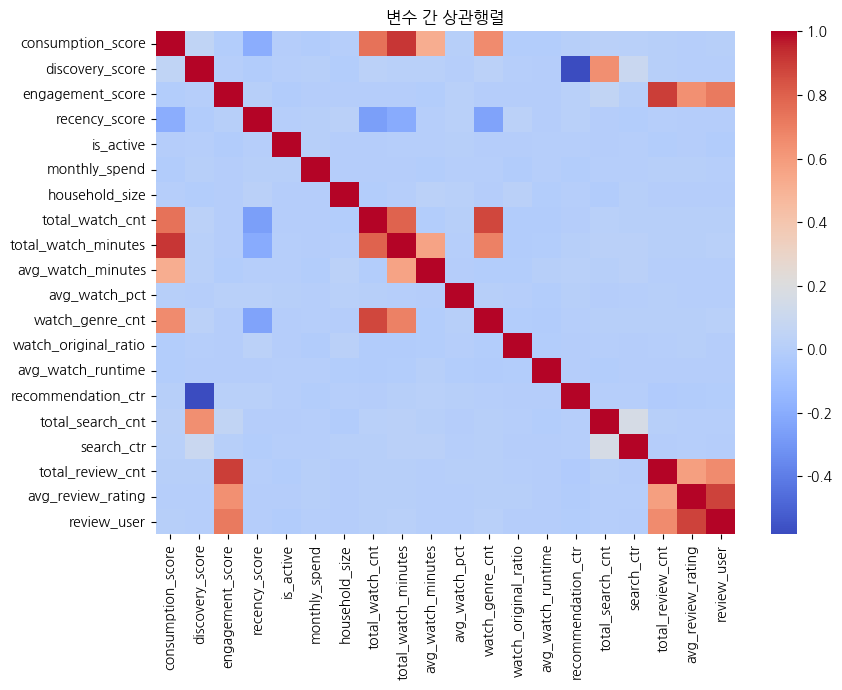

In [23]:
# 상관분석
numeric_cols = df_clean.select_dtypes(include=np.number).columns

# (1) 상관행렬
corr = df_clean[numeric_cols].corr()

# (2) 히트맵
plt.figure(figsize=(9, 7))
sns.heatmap(corr, cmap='coolwarm')
plt.title("변수 간 상관행렬", fontsize=12)
plt.tight_layout()
plt.show()

**모델링 방향**

is_active와 데이터 간 상관관계가 낮아 현재 변수로는 이탈 여부를 구분해내기 어려움. (행동과 지표 사이의 시차로 인해 모델이 명확한 인과관계를 학습하지 못했을 가능성이 있음. 사용자가 앱에 방문하지 않고 시청 활동을 멈추었더라도, 구독 해지를 하기 전까지는 데이터상 구독 유지를 하고 있는 사용자로 분류되기 때문.)

=> 돈은 내고 있지만 시청은 하지 않고 있는 **Dormant User** 세그먼트를 타겟으로 예측 모델링을 하고자 함.

- Dormant User는 마지막 시청 후 경과 시간이 긴 사용자 집단으로, 잠재적 이탈 위험군이라고 판단됨.

- 모델링을 통해 어떤 행동이 사용자의 휴면을 감지할 수 있는지 알아보고, 휴면으로 분류되는 사용자에 대해 선제적인 조치를 취하여, 궁극적으로는 이탈하는 사용자를 줄이는 것을 목표로 함.

In [24]:
# 타겟 생성
df_clean['target'] = (df_clean['segment'] == 'Dormant User').astype(int)

# 변수 선택 (사용자 속성과 행동)
features = [
    'age', 'gender', 'subscription_plan', 'monthly_spend', 'primary_device','household_size',
    'total_watch_cnt', 'total_watch_minutes', 'avg_watch_pct',
    'watch_genre_cnt', 'watch_original_ratio',
    'recommendation_ctr',
    'total_search_cnt', 'search_ctr',
    'total_review_cnt'
]
X = pd.get_dummies(df_clean[features], drop_first=True) # 범주형 변수 인코딩
y = df_clean['target']

# 타겟 분포 확인 ✅ 추가
print(y.value_counts(normalize=True))

# 데이터 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# 스케일링 (로지스틱 회귀용)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

target
0    0.8288
1    0.1712
Name: proportion, dtype: float64


In [25]:
# # 타겟 생성
# df_clean['target'] = (df_clean['segment'] == 'Dormant User').astype(int)

# # 타겟 분포 확인 ✅ 추가
# print(y.value_counts(normalize=True))

# # 변수 선택 (score 계열 추가)
# features = [
#     # 사용자 속성
#     'age', 'gender', 'subscription_plan', 'monthly_spend',
#     'primary_device', 'household_size',
#     # 시청 행동
#     'total_watch_cnt', 'total_watch_minutes', 'avg_watch_minutes',  # ✅ 추가
#     'avg_watch_pct', 'watch_genre_cnt', 'watch_original_ratio',
#     # 점수 계열 ✅ 추가
#     'recency_score', 'engagement_score', 'consumption_score',
#     # 추천/검색/리뷰
#     'recommendation_ctr', 'total_search_cnt', 'search_ctr', 'total_review_cnt'
# ]

# X = pd.get_dummies(df_clean[features], drop_first=True)
# y = df_clean['target']

# # # 불균형 확인 후 SMOTE 적용 여부 결정
# # from imblearn.over_sampling import SMOTE

# # X_train, X_test, y_train, y_test = train_test_split(
# #     X, y, test_size=0.3, random_state=42, stratify=y
# # )

# # 불균형 심할 경우 (이탈율 < 20%)
# # sm = SMOTE(random_state=42)
# # X_train, y_train = sm.fit_resample(X_train, y_train)

# # 스케일링
# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_test_scaled = scaler.transform(X_test)

# print(df_clean['target'].value_counts(normalize=True))

# 1단계 - 모델 학습


In [26]:
# ✅ 모델 정의
models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    'Decision Tree':       DecisionTreeClassifier(class_weight='balanced', random_state=42),
    'Random Forest':       RandomForestClassifier(class_weight='balanced', n_estimators=200, random_state=42),
    'GBM':                 GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, random_state=42),
    'XGBoost':             XGBClassifier(scale_pos_weight=4, n_estimators=200, learning_rate=0.05, random_state=42, eval_metric='logloss'),
    'LightGBM':            lgb.LGBMClassifier(class_weight='balanced', n_estimators=200, learning_rate=0.05, random_state=42)
}

# 2단계 - 모델 평가 (일괄 비교)


In [27]:
results = []

for name, model in models.items():

    # 로지스틱 회귀는 스케일링된 데이터 사용
    if name == 'Logistic Regression':
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        y_prob = model.predict_proba(X_test_scaled)[:, 1]
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        'Model'    : name,
        'Accuracy' : accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall'   : recall_score(y_test, y_pred),
        'F1'       : f1_score(y_test, y_pred),
        'AUC'      : roc_auc_score(y_test, y_prob)
    })

# 결과 DataFrame
result_df = pd.DataFrame(results).sort_values('AUC', ascending=False)
print(result_df.round(4))

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 1198, number of negative: 5802
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001601 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 992
[LightGBM] [Info] Number of data points in the train set: 7000, number of used features: 29
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
                 Model  Accuracy  Precision  Recall      F1     AUC
3                  GBM    0.8633     0.6605  0.4163  0.5107  0.9094
4              XGBoost    0.8113     0.4718  0.8463  0.6058  0.9086
5             LightGBM    0.8177     0.4807  0.7996  0.6004  0.9082
2        Random Forest    0.8497     0.6684  0.2432  0.3566  0.8969
0  Logistic Regression    0.7467     0.3835  0.7879  0.5159  0.8371
1        Decision Tree  

# 3단계 - 교차검증 (StratifiedKFold)

In [28]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("=== 교차검증 AUC ===")
for name, model in models.items():
    X_cv = X_train_scaled if name == 'Logistic Regression' else X_train
    scores = cross_val_score(model, X_cv, y_train, cv=skf, scoring='roc_auc')
    print(f"{name:25s} AUC: {scores.mean():.4f} (+/- {scores.std():.4f})")

=== 교차검증 AUC ===
Logistic Regression       AUC: 0.8308 (+/- 0.0164)
Decision Tree             AUC: 0.6718 (+/- 0.0203)
Random Forest             AUC: 0.8908 (+/- 0.0164)
GBM                       AUC: 0.9036 (+/- 0.0119)
XGBoost                   AUC: 0.9012 (+/- 0.0114)
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 959, number of negative: 4641
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000290 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 989
[LightGBM] [Info] Number of data points in the train set: 5600, number of used features: 29
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Inf

# 3단계-1 - 과적합 판정 확인

In [29]:
# ✅ 분석 대상 4개 모델
target_models = {
    'LightGBM'     : models['LightGBM'],
    'XGBoost'      : models['XGBoost'],
    'Random Forest': models['Random Forest'],
    'Decision Tree': models['Decision Tree']
}
# 모델 학습
for name, model in target_models.items():
    model.fit(X_train, y_train)

print("=== Train AUC vs Test AUC 과적합 판정 ===")
print(f"{'Model':15s} {'Train AUC':>10} {'Test AUC':>10} {'Gap':>8} {'판정':>12}")
print("-" * 62)

for name, model in target_models.items():
    train_prob = model.predict_proba(X_train)[:, 1]
    test_prob  = model.predict_proba(X_test)[:, 1]
    train_auc  = roc_auc_score(y_train, train_prob)
    test_auc   = roc_auc_score(y_test,  test_prob)
    gap        = train_auc - test_auc
    판정        = "✅ 안정적" if gap < 0.05 else "⚠️ 과적합 의심"
    print(f"{name:15s} {train_auc:>10.4f} {test_auc:>10.4f} {gap:>8.4f} {판정:>12}")


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 1198, number of negative: 5802
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000375 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 992
[LightGBM] [Info] Number of data points in the train set: 7000, number of used features: 29
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
=== Train AUC vs Test AUC 과적합 판정 ===
Model            Train AUC   Test AUC      Gap           판정
--------------------------------------------------------------
LightGBM            0.9922     0.9082   0.0840    ⚠️ 과적합 의심
XGBoost             0.9723     0.9086   0.0638    ⚠️ 과적합 의심
Random Forest       1.0000     0.8969   0.1031    ⚠️ 과적합 의심
Decision Tree       1.0000  

# 4단계 - ROC 커브 시각화


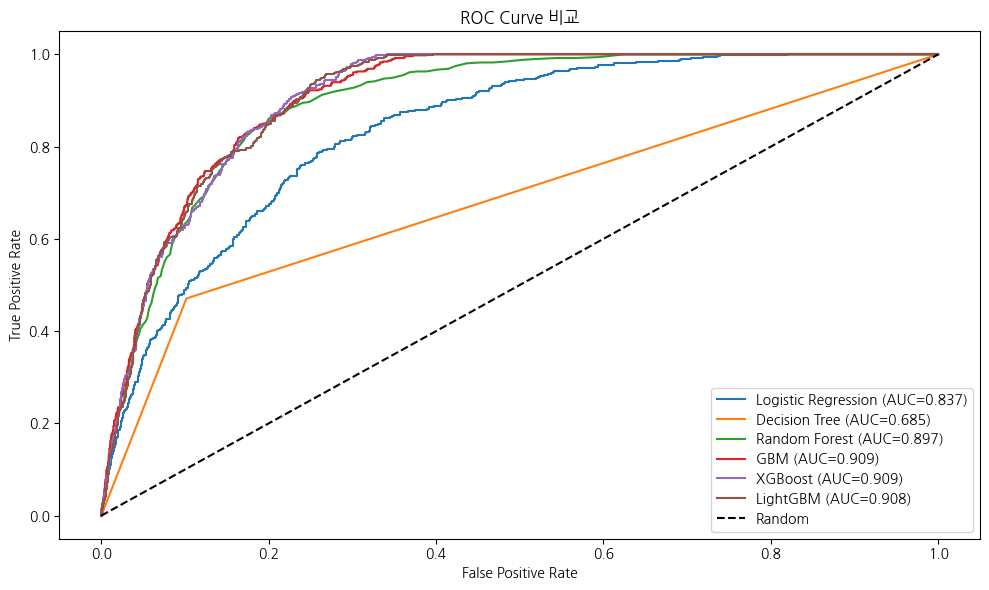

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for name, model in models.items():
    X_vis = X_test_scaled if name == 'Logistic Regression' else X_test
    y_prob = model.predict_proba(X_vis)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')

plt.plot([0,1], [0,1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve 비교')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# 5단계 - 최종 모델 Feature Importance


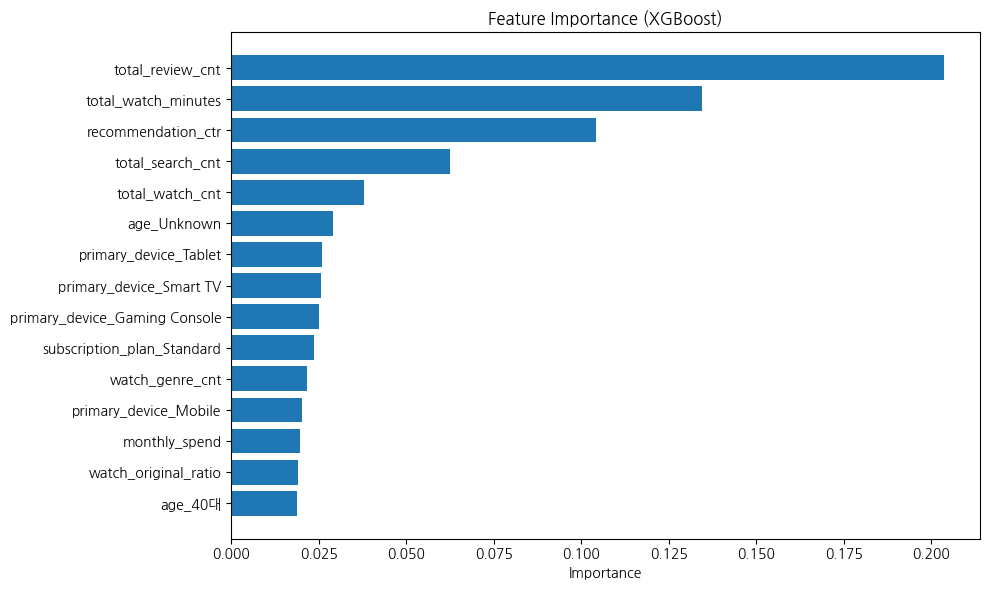

In [31]:
# 최종 모델 : XGBoost
best_model = models['XGBoost']

importance_df = pd.DataFrame({
    'feature'   : X_train.columns,
    'importance': best_model.feature_importances_
}).sort_values('importance', ascending=False).head(15)

plt.figure(figsize=(10, 6))
plt.barh(importance_df['feature'], importance_df['importance'])
plt.gca().invert_yaxis()
plt.title('Feature Importance (XGBoost)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

---

### 📊 전체 흐름 요약
```
모델 6개 학습
    ↓
정확도 / F1 / AUC 일괄 비교  →  result_df
    ↓
StratifiedKFold 교차검증      →  과적합 여부 확인
    ↓
ROC Curve 시각화              →  모델 간 성능 비교
    ↓
Feature Importance            →  이탈 방지 전략 도출

# ✅ STEP 1. 상위 중요 변수 선택 (Feature Importance 기반)


In [32]:
top_features = [
    'total_review_cnt',
    'total_watch_minutes',
    'recommendation_ctr',
    'total_search_cnt',
    'total_watch_cnt'
]

# X, y 정의 (df는 기존 데이터프레임)
X = df[top_features]
y = df_clean['target']  # ← 실제 타겟 컬럼명으로 변경

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"타겟 비율 (Train): {y_train.value_counts(normalize=True).to_dict()}")


Train: (8000, 5), Test: (2000, 5)
타겟 비율 (Train): {0: 0.82875, 1: 0.17125}


# ✅ STEP 2. 하이퍼파라미터 튜닝 (RandomizedSearchCV)
#            과적합 억제에 중점을 둔 파라미터 범위 설정

In [33]:
param_dist = {
    'n_estimators':    [100, 200, 300, 500],
    'max_depth':       [2, 3, 4, 5],          # 낮을수록 과적합 억제
    'learning_rate':   [0.01, 0.03, 0.05, 0.1],
    'subsample':       [0.6, 0.7, 0.8, 1.0],  # 행 샘플링
    'colsample_bytree':[0.6, 0.7, 0.8, 1.0],  # 열 샘플링
    'min_child_weight':[1, 3, 5, 7],           # min_samples와 유사, 클수록 과적합 억제
    'reg_alpha':       [0, 0.01, 0.1, 1.0],   # L1 정규화
    'reg_lambda':      [0.5, 1.0, 2.0, 5.0],  # L2 정규화
    'gamma':           [0, 0.1, 0.3, 0.5],    # 분기 최소 손실 감소량
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

base_model = XGBClassifier(
    scale_pos_weight=int((y_train == 0).sum() / (y_train == 1).sum()),  # 불균형 보정
    eval_metric='auc',
    random_state=42,
    n_jobs=-1
)

search = RandomizedSearchCV(
    estimator=base_model,
    param_distributions=param_dist,
    n_iter=50,              # 탐색 횟수 (시간 여유 있으면 100으로)
    scoring='roc_auc',
    cv=cv,
    random_state=42,
    verbose=1,
    n_jobs=-1
)

search.fit(X_train, y_train)

print("\n✅ 최적 하이퍼파라미터:")
for k, v in search.best_params_.items():
    print(f"  {k}: {v}")
print(f"\n✅ CV Best AUC: {search.best_score_:.4f}")


Fitting 5 folds for each of 50 candidates, totalling 250 fits

✅ 최적 하이퍼파라미터:
  subsample: 0.8
  reg_lambda: 1.0
  reg_alpha: 0.1
  n_estimators: 200
  min_child_weight: 1
  max_depth: 5
  learning_rate: 0.03
  gamma: 0.5
  colsample_bytree: 0.7

✅ CV Best AUC: 0.9064


# ✅ STEP 3. 최적 모델로 재학습 및 과적합 갭 확인


In [34]:
best_model = search.best_estimator_

train_auc = roc_auc_score(y_train, best_model.predict_proba(X_train)[:, 1])
test_auc  = roc_auc_score(y_test,  best_model.predict_proba(X_test)[:, 1])

print("\n=== 과적합 갭 확인 ===")
print(f"  Train AUC : {train_auc:.4f}")
print(f"  Test  AUC : {test_auc:.4f}")
print(f"  Gap       : {train_auc - test_auc:.4f}  {'⚠️ 과적합 의심' if (train_auc - test_auc) > 0.05 else '✅ 양호'}")


=== 과적합 갭 확인 ===
  Train AUC : 0.9225
  Test  AUC : 0.9172
  Gap       : 0.0054  ✅ 양호


# ✅ STEP 4. 임계값(Threshold) 탐색 — Precision-Recall 밸런스


In [35]:
y_prob = best_model.predict_proba(X_test)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob)

# F1이 최대인 임계값 탐색
f1_scores = 2 * precisions[:-1] * recalls[:-1] / (precisions[:-1] + recalls[:-1] + 1e-9)
best_threshold_f1  = thresholds[np.argmax(f1_scores)]

# Recall >= 0.75를 만족하면서 Precision이 최대인 임계값 탐색
mask = recalls[:-1] >= 0.75
best_threshold_rec = thresholds[mask][np.argmax(precisions[:-1][mask])] if mask.any() else best_threshold_f1

print(f"\n✅ F1 최대 임계값    : {best_threshold_f1:.4f}")
print(f"✅ Recall≥0.75 임계값: {best_threshold_rec:.4f}")



✅ F1 최대 임계값    : 0.6416
✅ Recall≥0.75 임계값: 0.6416


# ✅ STEP 5. 임계값별 최종 성능 비교


In [36]:
def evaluate_threshold(y_true, y_prob, threshold, label=""):
    y_pred = (y_prob >= threshold).astype(int)
    print(f"\n--- {label} (threshold={threshold:.4f}) ---")
    print(f"  Accuracy : {accuracy_score(y_true, y_pred):.4f}")
    print(f"  Precision: {precision_score(y_true, y_pred, zero_division=0):.4f}")
    print(f"  Recall   : {recall_score(y_true, y_pred):.4f}")
    print(f"  F1       : {f1_score(y_true, y_pred):.4f}")
    print(f"  AUC      : {roc_auc_score(y_true, y_prob):.4f}")
    print(confusion_matrix(y_true, y_pred))
    return y_pred

print("\n=== 임계값별 성능 비교 ===")
evaluate_threshold(y_test, y_prob, 0.5,                  "기본 (0.5)")
evaluate_threshold(y_test, y_prob, best_threshold_f1,    "F1 최대")
evaluate_threshold(y_test, y_prob, best_threshold_rec,   "Recall≥0.75 최대 Precision")



=== 임계값별 성능 비교 ===

--- 기본 (0.5) (threshold=0.5000) ---
  Accuracy : 0.8050
  Precision: 0.4632
  Recall   : 0.8830
  F1       : 0.6076
  AUC      : 0.9172
[[1308  350]
 [  40  302]]

--- F1 최대 (threshold=0.6416) ---
  Accuracy : 0.8590
  Precision: 0.5641
  Recall   : 0.7719
  F1       : 0.6519
  AUC      : 0.9172
[[1454  204]
 [  78  264]]

--- Recall≥0.75 최대 Precision (threshold=0.6416) ---
  Accuracy : 0.8590
  Precision: 0.5641
  Recall   : 0.7719
  F1       : 0.6519
  AUC      : 0.9172
[[1454  204]
 [  78  264]]


array([0, 0, 0, ..., 1, 1, 0])

# ✅ STEP 6. 혼동 행렬

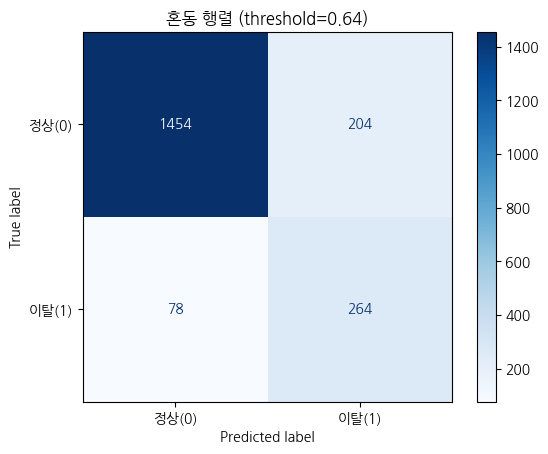

FN (미탐지 이탈 유저) : 78명
TP (정확히 탐지한 이탈 유저) : 264명
Recall : 0.7719


In [37]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred = (best_model.predict_proba(X_test)[:, 1] >= best_threshold_f1).astype(int)

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['정상(0)', '이탈(1)'])
disp.plot(cmap='Blues')
plt.title(f'혼동 행렬 (threshold={best_threshold_f1:.2f})')
plt.show()

# FN 직접 출력
TN, FP, FN, TP = cm.ravel()
print(f"FN (미탐지 이탈 유저) : {FN}명")
print(f"TP (정확히 탐지한 이탈 유저) : {TP}명")
print(f"Recall : {TP / (TP + FN):.4f}")

# ✅ STEP 7. 시각화


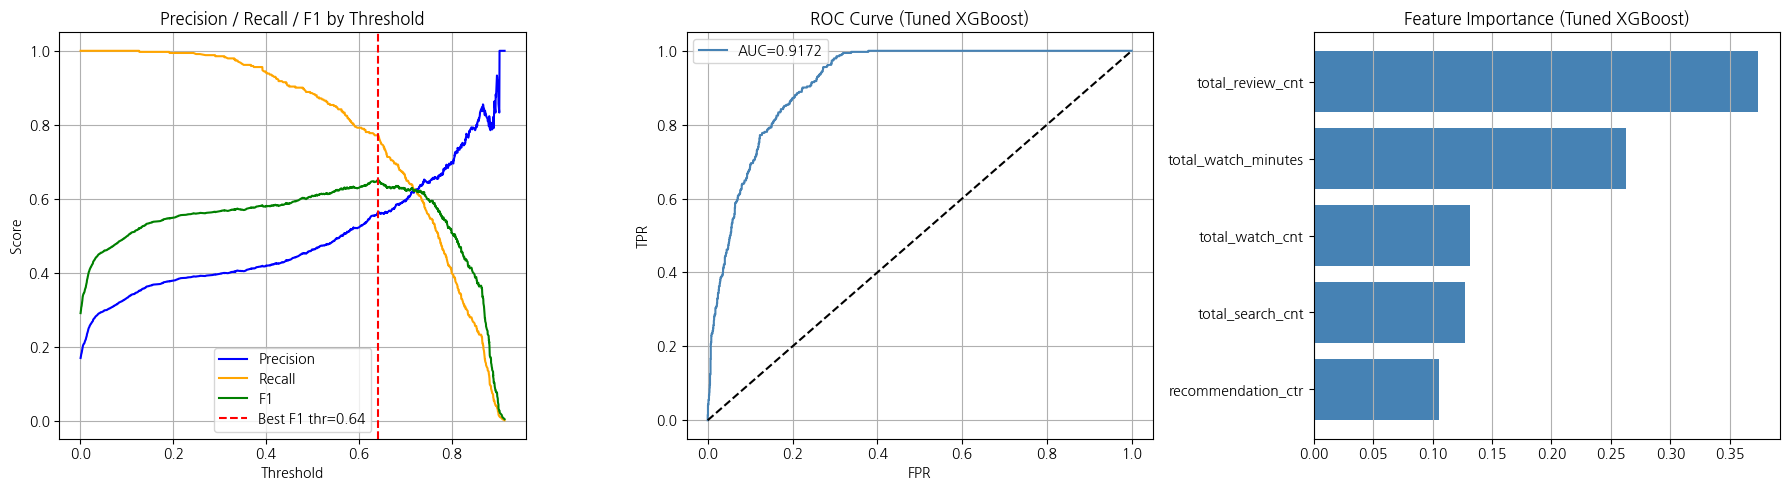


✅ 분석 완료!


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (1) Precision-Recall Curve
axes[0].plot(thresholds, precisions[:-1], label='Precision', color='blue')
axes[0].plot(thresholds, recalls[:-1],    label='Recall',    color='orange')
axes[0].plot(thresholds, f1_scores,       label='F1',        color='green')
axes[0].axvline(best_threshold_f1, color='red', linestyle='--', label=f'Best F1 thr={best_threshold_f1:.2f}')
axes[0].set_xlabel('Threshold'); axes[0].set_ylabel('Score')
axes[0].set_title('Precision / Recall / F1 by Threshold')
axes[0].legend(); axes[0].grid(True)

# (2) ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, color='steelblue', label=f'AUC={test_auc:.4f}')
axes[1].plot([0,1],[0,1],'k--')
axes[1].set_xlabel('FPR'); axes[1].set_ylabel('TPR')
axes[1].set_title('ROC Curve (Tuned XGBoost)'); axes[1].legend(); axes[1].grid(True)

# (3) Feature Importance
feat_imp = pd.Series(best_model.feature_importances_, index=top_features).sort_values()
axes[2].barh(feat_imp.index, feat_imp.values, color='steelblue')
axes[2].set_title('Feature Importance (Tuned XGBoost)'); axes[2].grid(True, axis='x')

plt.tight_layout()
plt.savefig('xgboost_tuned_result.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# 튜닝된 XGBoost(best_model)로 교체
target_models = {
    'LightGBM'        : models['LightGBM'],
    'XGBoost (tuned)' : best_model,          # ← 튜닝된 모델로 교체
    'Random Forest'   : models['Random Forest'],
    'Decision Tree'   : models['Decision Tree']
}

# 모델 학습 (best_model은 이미 학습 완료라 fit 불필요하지만 나머지는 필요)
for name, model in target_models.items():
    if name != 'XGBoost (tuned)':            # ← 튜닝 모델은 재학습 제외
        model.fit(X_train, y_train)

print("=== Train AUC vs Test AUC 과적합 판정 ===")
print(f"{'Model':20s} {'Train AUC':>10} {'Test AUC':>10} {'Gap':>8} {'판정':>12}")
print("-" * 67)

for name, model in target_models.items():
    train_prob = model.predict_proba(X_train)[:, 1]
    test_prob  = model.predict_proba(X_test)[:, 1]
    train_auc  = roc_auc_score(y_train, train_prob)
    test_auc   = roc_auc_score(y_test,  test_prob)
    gap        = train_auc - test_auc
    판정        = "✅ 안정적" if gap < 0.05 else "⚠️ 과적합 의심"
    print(f"{name:20s} {train_auc:>10.4f} {test_auc:>10.4f} {gap:>8.4f} {판정:>12}")

[LightGBM] [Info] Number of positive: 1370, number of negative: 6630
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000166 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 333
[LightGBM] [Info] Number of data points in the train set: 8000, number of used features: 5
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
=== Train AUC vs Test AUC 과적합 판정 ===
Model                 Train AUC   Test AUC      Gap           판정
-------------------------------------------------------------------
LightGBM                 0.9564     0.9130   0.0434        ✅ 안정적
XGBoost (tuned)          0.9225     0.9172   0.0054        ✅ 안정적
Random Forest            1.0000     0.9008   0.0992    ⚠️ 과적합 의심
Decision Tree            0.9999     0.6983   0.3017    ⚠️ 과적합 의심


# KS / IV / PSI 종합 분석

# 1. KS 통계량


KS 통계량 : 0.6835
KS p-value: 0.0000


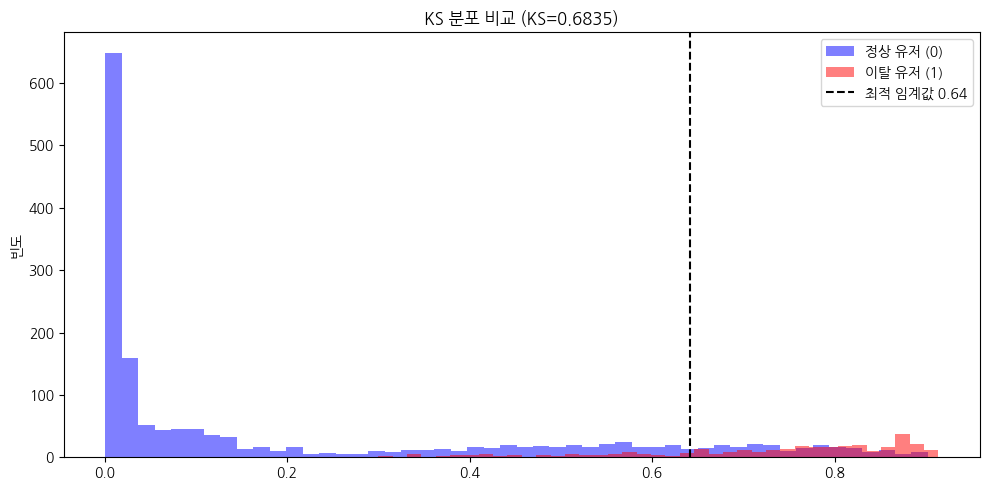

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# XGBoost 예측 확률
y_prob = best_model.predict_proba(X_test)[:, 1]

# 이탈(1) vs 정상(0) 확률 분리
prob_churn  = y_prob[y_test == 1]
prob_normal = y_prob[y_test == 0]

# KS 계산
ks_stat, ks_pvalue = stats.ks_2samp(prob_churn, prob_normal)
print(f"KS 통계량 : {ks_stat:.4f}")
print(f"KS p-value: {ks_pvalue:.4f}")

# KS 시각화
plt.figure(figsize=(10, 5))
plt.hist(prob_normal, bins=50, alpha=0.5, label='정상 유저 (0)', color='blue')
plt.hist(prob_churn,  bins=50, alpha=0.5, label='이탈 유저 (1)', color='red')
plt.axvline(x=best_threshold_f1, color='black', linestyle='--',
            label=f'최적 임계값 {best_threshold_f1:.2f}')  # 0.5 대신 튜닝된 임계값 plt.xlabel('예측 확률')
plt.ylabel('빈도')
plt.title(f'KS 분포 비교 (KS={ks_stat:.4f})')
plt.legend()
plt.tight_layout()
plt.show()

# 2. IV (Information Value)


                feature      IV
1   total_watch_minutes  2.2316
0      total_review_cnt  1.7430
4       total_watch_cnt  1.0704
6       watch_genre_cnt  0.7612
3      total_search_cnt  0.1392
2    recommendation_ctr  0.0343
5         avg_watch_pct  0.0318
7  watch_original_ratio  0.0255
8         monthly_spend  0.0082


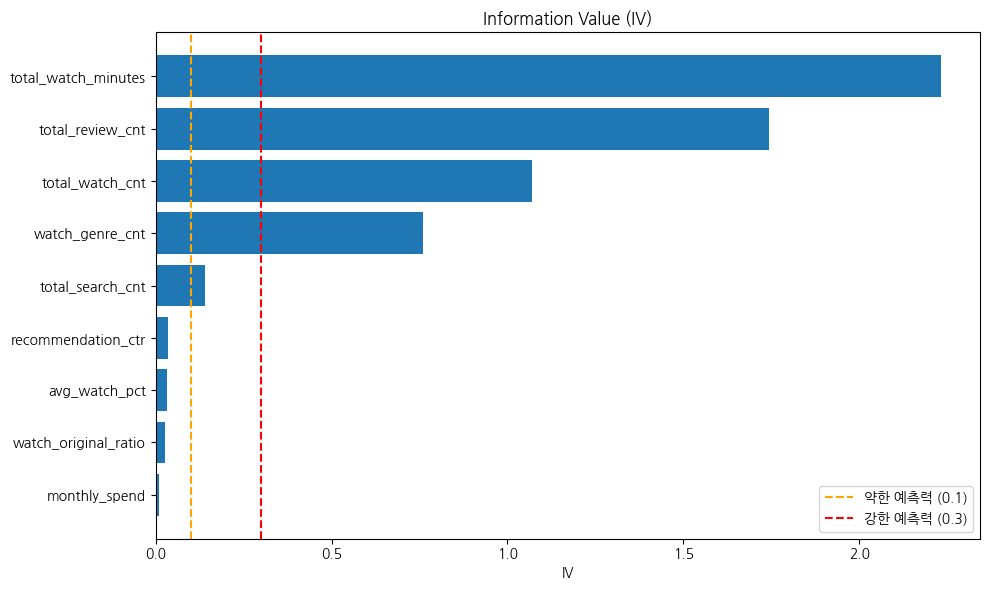

In [ ]:
def calc_iv(df, feature, target, bins=10):
    df = df.copy()

    # 수치형 변수 bin 처리
    if df[feature].dtype in ['float64', 'int64']:
        df['bin'] = pd.qcut(df[feature], q=bins, duplicates='drop')
    else:
        df['bin'] = df[feature]

    grouped = df.groupby('bin')[target].agg(['sum', 'count'])
    grouped.columns = ['event', 'total']
    grouped['non_event'] = grouped['total'] - grouped['event']

    total_event     = grouped['event'].sum()
    total_non_event = grouped['non_event'].sum()

    grouped['dist_event']     = grouped['event']     / total_event
    grouped['dist_non_event'] = grouped['non_event'] / total_non_event

    # 0 나눗셈 방지
    grouped['dist_event']     = grouped['dist_event'].replace(0, 0.0001)
    grouped['dist_non_event'] = grouped['dist_non_event'].replace(0, 0.0001)

    grouped['woe'] = np.log(grouped['dist_event'] / grouped['dist_non_event'])
    grouped['iv']  = (grouped['dist_event'] - grouped['dist_non_event']) * grouped['woe']

    return grouped['iv'].sum()

# 수치형 변수에 대해 IV 계산
num_features = [
    'total_review_cnt', 'total_watch_minutes', 'recommendation_ctr',
    'total_search_cnt', 'total_watch_cnt', 'avg_watch_pct',
    'watch_genre_cnt', 'watch_original_ratio', 'monthly_spend'
]

# cf)
# num_features = top_features  # ['total_review_cnt', 'total_watch_minutes',
                              #  'recommendation_ctr', 'total_search_cnt', 'total_watch_cnt']

df_iv = df_clean.copy()
iv_results = []

for col in num_features:
    iv = calc_iv(df_iv, col, 'target')
    iv_results.append({'feature': col, 'IV': round(iv, 4)})

iv_df = pd.DataFrame(iv_results).sort_values('IV', ascending=False)
print(iv_df)

# IV 시각화
plt.figure(figsize=(10, 6))
plt.barh(iv_df['feature'], iv_df['IV'])
plt.gca().invert_yaxis()
plt.axvline(x=0.1, color='orange', linestyle='--', label='약한 예측력 (0.1)')
plt.axvline(x=0.3, color='red',    linestyle='--', label='강한 예측력 (0.3)')
plt.title('Information Value (IV)')
plt.xlabel('IV')
plt.legend()
plt.tight_layout()
plt.show()

# 3. PSI (Population Stability Index)



PSI 점수: 0.0084
✅ 안정적 (PSI < 0.1) - 모델 그대로 사용 가능


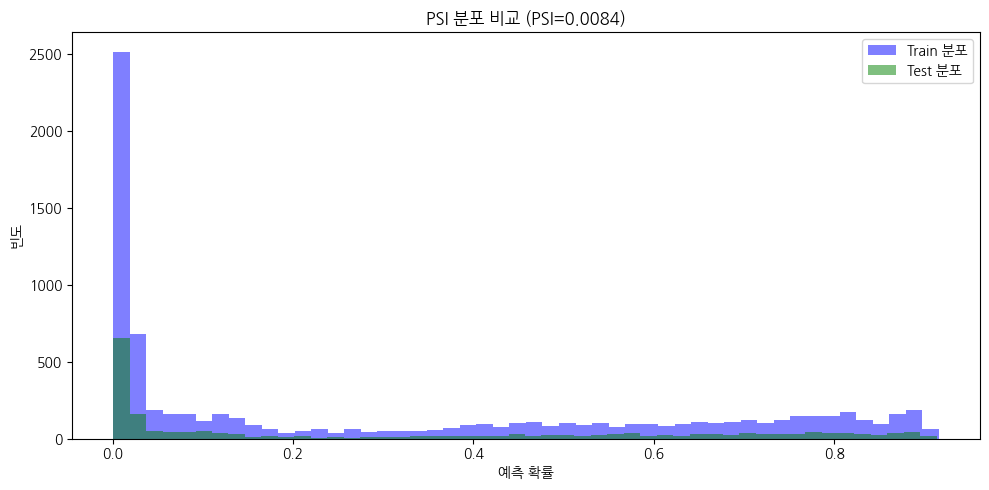

In [ ]:
def calc_psi(expected, actual, bins=10):
    # 분위수 기준으로 구간 설정
    breakpoints = np.percentile(expected, np.linspace(0, 100, bins + 1))
    breakpoints = np.unique(breakpoints)

    expected_cnt = np.histogram(expected, bins=breakpoints)[0]
    actual_cnt   = np.histogram(actual,   bins=breakpoints)[0]

    # 비율 계산
    expected_pct = expected_cnt / len(expected)
    actual_pct   = actual_cnt   / len(actual)

    # 0 방지
    expected_pct = np.where(expected_pct == 0, 0.0001, expected_pct)
    actual_pct   = np.where(actual_pct   == 0, 0.0001, actual_pct)

    psi_values = (actual_pct - expected_pct) * np.log(actual_pct / expected_pct)

    return psi_values.sum()

# train 확률 vs test 확률로 PSI 계산
y_prob_train = best_model.predict_proba(X_train)[:, 1]
y_prob_test  = best_model.predict_proba(X_test)[:, 1]

psi_score = calc_psi(y_prob_train, y_prob_test)
print(f"\nPSI 점수: {psi_score:.4f}")

# PSI 판단
if psi_score < 0.1:
    print("✅ 안정적 (PSI < 0.1) - 모델 그대로 사용 가능")
elif psi_score < 0.2:
    print("⚠️ 주의 필요 (0.1 ≤ PSI < 0.2) - 모니터링 필요")
else:
    print("❌ 불안정 (PSI ≥ 0.2) - 모델 재학습 필요")

# PSI 시각화
plt.figure(figsize=(10, 5))
plt.hist(y_prob_train, bins=50, alpha=0.5, label='Train 분포', color='blue')
plt.hist(y_prob_test,  bins=50, alpha=0.5, label='Test 분포',  color='green')
plt.xlabel('예측 확률')
plt.ylabel('빈도')
plt.title(f'PSI 분포 비교 (PSI={psi_score:.4f})')
plt.legend()
plt.tight_layout()
plt.show()

# 4. 종합 요약


In [ ]:
print("=" * 40)
print("      KS / IV / PSI 종합 요약")
print("=" * 40)
print(f"KS 통계량 : {ks_stat:.4f}")
print(f"PSI 점수  : {psi_score:.4f}")
print()
print("[IV 상위 5개 변수]")
print(iv_df.head())
print("=" * 40)


      KS / IV / PSI 종합 요약
KS 통계량 : 0.6835
PSI 점수  : 0.0084

[IV 상위 5개 변수]
               feature      IV
1  total_watch_minutes  2.2316
0     total_review_cnt  1.7430
4      total_watch_cnt  1.0704
3     total_search_cnt  0.1392
2   recommendation_ctr  0.0343


### 📊 결과 판단 기준

**KS 기준**
```
0.4 이상  → 우수한 변별력 ✅
0.2~0.4  → 보통
0.2 미만  → 낮음 ❌
```

**IV 기준**
```
0.5 이상  → 매우 강한 예측력
0.3~0.5  → 강한 예측력 ✅
0.1~0.3  → 중간 예측력
0.1 미만  → 약한 예측력 ❌
```

**PSI 기준**
```
0.1 미만  → 안정적, 그대로 사용 ✅
0.1~0.2  → 주의, 모니터링 필요 ⚠️
0.2 이상  → 불안정, 재학습 필요 ❌